In [1]:
import pandas as pd

data_path = "data/iiit5k-words"
traindata = pd.read_csv(f'{data_path}/traindata.csv')
trainCharBound = pd.read_csv(f'{data_path}/trainCharBound.csv')
testdata = pd.read_csv(f'{data_path}/testdata.csv')
testCharBound = pd.read_csv(f'{data_path}/testCharBound.csv')

In [2]:
trainCharBound.iloc[0]

ImgName                                     train/1009_2.png
chars                                                    You
charBB     [[ 5.  5. 21. 36.]\n [25. 15. 24. 26.]\n [49. ...
Name: 0, dtype: object

In [3]:
traindata.iloc[0]['GroundTruth']

'YOU'

In [4]:
type(trainCharBound.iloc[1]['chars'])

str

In [5]:
len(traindata)

2000

In [6]:
len(testCharBound)

3000

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split

data_path = "data/iiit5k-words"
trainvaldata = pd.read_csv(f'{data_path}/trainCharBound.csv')
testdata = pd.read_csv(f'{data_path}/testCharBound.csv')

In [3]:
from src.rec_model.model import CRNN2

In [8]:
traindata, valdata = train_test_split(trainvaldata,test_size=0.1,random_state=42,shuffle=True)

In [9]:
traindata.reset_index(inplace=True)
valdata.reset_index(inplace=True)
testdata.reset_index(inplace=True)

In [10]:
traindata.drop(columns=['charBB', 'index'], inplace=True)
valdata.drop(columns=['charBB', 'index'], inplace=True)
testdata.drop(columns=['charBB', 'index'], inplace=True)

In [11]:
traindata.head()

,ImgName,chars
0,train/927_2.png,BLAZE
1,train/2429_1.png,SANDY
2,train/2055_32.png,numbers
3,train/2624_3.png,2
4,train/2311_5.png,GENOAS


In [12]:
valdata.head()

,ImgName,chars
0,train/921_2.png,DATO
1,train/2254_11.png,Tall
2,train/529_13.png,AM
3,train/5016_4.png,PAINS
4,train/5184_1.png,THEYRE


In [13]:
testdata.head()

,ImgName,chars
0,test/1002_1.png,PRIVATE
1,test/1002_2.png,PARKING
2,test/1009_1.png,Salutes
3,test/100_1.png,DOLCE
4,test/100_2.png,GABBANA


In [14]:
prefix_path = "data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K"

In [15]:
colum_name = ''
traindata['ImgName'] = prefix_path + '/' + traindata['ImgName']
valdata['ImgName'] = prefix_path + '/' + valdata['ImgName']
testdata['ImgName'] = prefix_path + '/' + testdata['ImgName']

In [16]:
valdata.head()

,ImgName,chars
0,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,DATO
1,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,Tall
2,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,AM
3,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,PAINS
4,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,THEYRE


In [17]:
from PIL import Image

In [18]:
img = Image.open(testdata.iloc[0]['ImgName'])

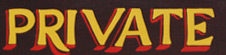

In [19]:
img

In [1]:
save_path = "data/processed"

In [2]:
import os

In [3]:
os.makedirs(save_path, exist_ok=True)

In [4]:
traindata.to_csv(f'{save_path}/train.csv', index=False)
valdata.to_csv(f'{save_path}/val.csv', index=False)
testdata.to_csv(f'{save_path}/test.csv', index=False)

NameError: name 'traindata' is not defined

In [5]:
len(traindata), len(valdata), len(testdata)

NameError: name 'traindata' is not defined

In [25]:
valdata.head()

,ImgName,chars
0,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,DATO
1,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,Tall
2,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,AM
3,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,PAINS
4,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,THEYRE


In [1]:
data_path = "data/processed"

In [2]:
import pandas as pd
import cv2
traindata = pd.read_csv(f'{data_path}/train.csv')
valdata = pd.read_csv(f'{data_path}/val.csv')
testdata = pd.read_csv(f'{data_path}/test.csv')

In [3]:
traindata.head()

,ImgName,chars
0,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,BLAZE
1,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,SANDY
2,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,numbers
3,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,2
4,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,GENOAS


In [4]:
alltexts = list(traindata['chars'])

In [6]:
vocab_set = set(''.join(alltexts))
vocab_set.add('j')
vocab = sorted(vocab_set)

In [7]:
len(vocab)
ctoi = {c: i+1 for i, c in enumerate(vocab)}
itoc = {i: c for c, i in ctoi.items()}

In [8]:
import torch.nn.functional as F
import torch

In [9]:
def encode(txt):
    dig_lst = []
    
    for char in (txt):
        if char in ctoi:
            dig_lst.append(ctoi.get(char))
    return torch.tensor(dig_lst, dtype=torch.long)

In [10]:
x = encode('abcdejjg')

In [11]:
x

tensor([37, 38, 39, 40, 41, 46, 46, 43])

In [12]:
import torch.nn.functional as F
from torchvision.io import read_image, ImageReadMode

def process_single_sample(img_path, label):
    # 1-2. Read + decode as grayscale -> uint8, shape [1, H, W]
    img = read_image(img_path, mode=ImageReadMode.GRAY)
    print(img.shape)

    # 3. Convert to float32 in [0, 1]
    img = img.float() / 255.0

    # 4. Resize to (32, 128)
    img = F.interpolate(img.unsqueeze(0), size=(32, 128),
                        mode="bilinear", align_corners=False).squeeze(0)

    return img,label

In [13]:
traindata.head()

,ImgName,chars
0,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,BLAZE
1,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,SANDY
2,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,numbers
3,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,2
4,data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/trai...,GENOAS


In [14]:
image_path, text = traindata.iloc[0]

In [15]:
image_path, text

('data/iiit5k-words/IIIT5K-Word_V3.0/IIIT5K/train/927_2.png', 'BLAZE')

In [16]:
from torch.utils.data import Dataset, DataLoader

class OCRDataset(Dataset):
    def __init__(self, csv_path):
        super().__init__()
        self.data_csv = pd.read_csv(csv_path)

    def __len__(self):
        return len(self.data_csv)

    def __getitem__(self, idx):
        image_path, text = self.data_csv.iloc[idx]
        return process_single_sample(image_path, encode(text))

In [17]:
def collate(batch):
    images, labels = zip(*batch)
    target_lengths = torch.tensor(
        [len(label) for label in labels], dtype=torch.long
    )
    return torch.stack(images), torch.cat(labels), target_lengths

In [18]:
dataset = OCRDataset(f'{data_path}/val.csv')

In [19]:
train_dataloader = DataLoader(dataset=dataset, batch_size=16,shuffle=True, collate_fn=collate)

torch.Size([1, 155, 472])
torch.Size([1, 24, 65])
torch.Size([1, 28, 34])
torch.Size([1, 16, 18])
torch.Size([1, 24, 57])
torch.Size([1, 24, 35])
torch.Size([1, 27, 155])
torch.Size([1, 22, 27])
torch.Size([1, 23, 69])
torch.Size([1, 57, 171])
torch.Size([1, 72, 419])
torch.Size([1, 17, 88])
torch.Size([1, 27, 53])
torch.Size([1, 20, 55])
torch.Size([1, 62, 242])
torch.Size([1, 41, 82])


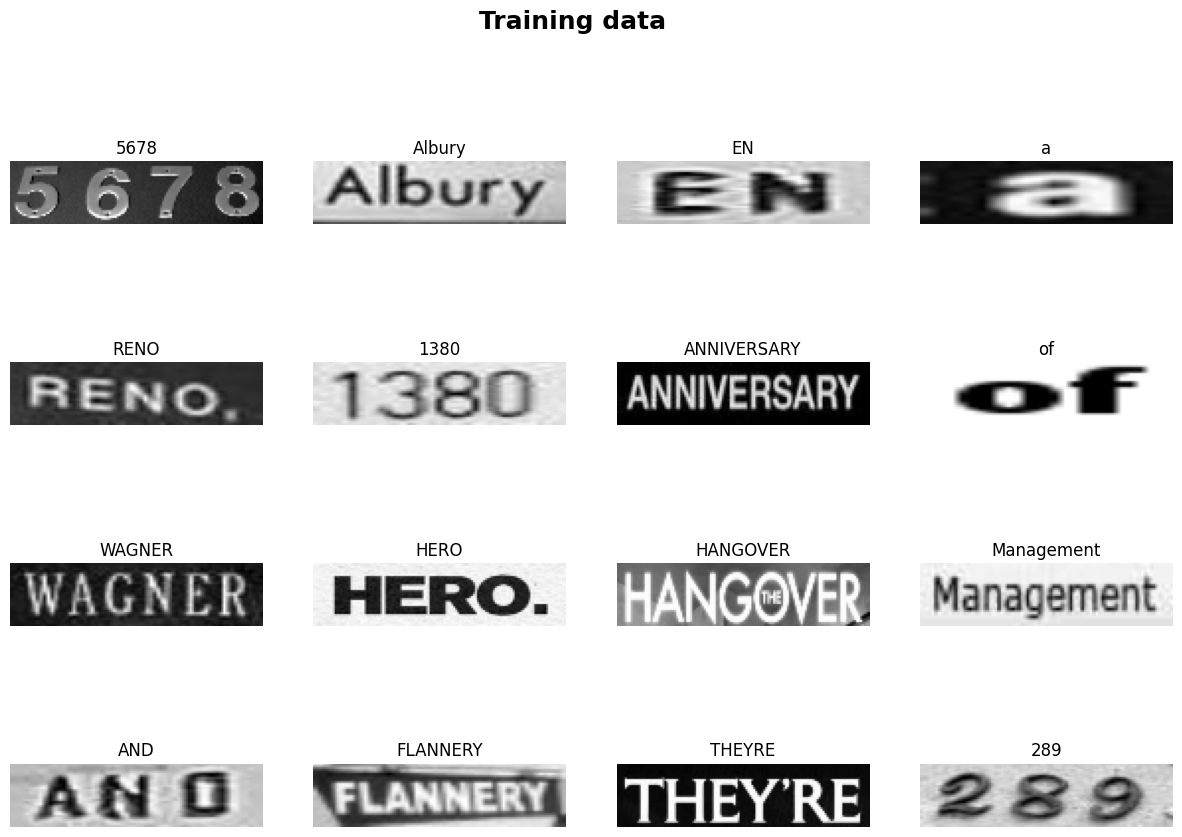

In [20]:
import torch
import matplotlib.pyplot as plt


def decode(ids):
    # skips 0 (blank/padding)
    string=""
    for i in ids:
        if int(i) in itoc:
            string = string + itoc[int(i)]
    return string

fig, ax = plt.subplots(4, 4, figsize=(15, 10))
fig.suptitle("Training data", weight="bold", size=18)

batch = next(iter(train_dataloader))
images, labels, target_lengths = batch   # images: [B, 1, 32, 128], labels: [B, L] padded

start=0
for i in range(16):
    img = (images[i, 0] * 255).byte().numpy()
    label = decode(labels[start:start+target_lengths[i]])
    start = start + target_lengths[i]

    ax[i // 4, i % 4].imshow(img, cmap="gray")
    ax[i // 4, i % 4].set_title(label)
    ax[i // 4, i % 4].axis("off")

plt.show()

In [21]:
import torch.nn as nn

In [22]:
H, W = 32, 128

class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels,kernel_size=3, padding=1, pool_size=(2, 2)):
        super().__init__()
        self.cnn = nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU()
        self.maxpool = nn.MaxPool2d(pool_size)
    def forward(self, x):
        x = self.cnn(x)
        x = self.batchnorm(x)
        x = self.act(x)
        x = self.maxpool(x)
        return x


class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        channels = [ 1, 64, 128, 256, 256]
        pooling = [(2, 2), (2, 2), (2, 1), (2, 1)]
        self.cnns = nn.ModuleList([CNNBlock(in_channels=channels[i], out_channels=channels[i+1], pool_size=pooling[i]) for i, pool_size in enumerate(pooling)])
        self.rnn1 = nn.LSTM(256 * (H // 16), 128, num_layers=2,
                           bidirectional=True, batch_first=True)
        self.rnn2 = nn.LSTM(256, 128, num_layers=2,
                                   bidirectional=True, batch_first=True)
        self.fc = nn.Linear(256, num_classes)
 
    def forward(self, x):
        for cnnblock in self.cnns:
            x = cnnblock(x)
        b, c, h, t = x.shape
        x = x.permute(0, 3, 1, 2).reshape(b, t, c * h)   # (B, T, C*h)
        
        x, _ = self.rnn1(x)
        x, _ = self.rnn2(x)
        return self.fc(x).permute(1, 0, 2)

In [23]:
model = CRNN(num_classes=len(vocab)+1)

In [36]:
sum(p.numel() for p in model.parameters())/1e6

2.820543

In [37]:
images.shape

torch.Size([16, 1, 32, 128])

In [38]:
out = model(images)

In [39]:
out.shape

torch.Size([32, 16, 63])

In [33]:
labels.shape

torch.Size([79])

In [34]:
labels.dtype

torch.int64

In [35]:
ctc_loss = nn.CTCLoss()

In [36]:
[0]*10

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [37]:
input_lengths = torch.tensor([out.shape[0]] * out.shape[1], dtype=torch.int64)
target_lengths = torch.tensor([labels.shape[1]] * labels.shape[0], dtype=torch.int64)

IndexError: tuple index out of range

In [38]:
input_lengths

tensor([32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32])

In [39]:
loss = ctc_loss(out, labels, input_lengths, target_lengths)

In [40]:
train_dataset = OCRDataset(f'{data_path}/train.csv')
val_dataset = OCRDataset(f'{data_path}/val.csv')

In [37]:
from itertools import groupby

In [28]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [43]:
BATCH, EPOCHS, LR = 128, 30, 1e-3
MAX_W=128

In [44]:
train_dataloader = DataLoader(train_dataset, batch_size=BATCH,shuffle=True, collate_fn=collate)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH, shuffle=True, collate_fn=collate)

In [24]:
def ctc_decoder(logits):
    probs = F.softmax(logits, dim=-1)
    labels = torch.argmax(probs, dim=-1)
    decoded_texts = []
    decoded_indices = []
    for i in range(labels.shape[0]):
        ans = ""
        idx = []
        
        ## merge repeats
        merged_list = [k for k,_ in groupby(labels[i])]
        
        ## remove blanks
        for p in merged_list:
            if p != 0:
                ans += itoc[int(p)]
                idx.append(int(p))

        
        decoded_texts.append(ans)
        decoded_indices.append(torch.tensor(idx, dtype=torch.int64))
        
    return decoded_texts, decoded_indices

In [25]:
from tqdm import tqdm

In [26]:
def eval(pred, gt, lens):
    lens = lens.tolist()
    bsz = len(pred)
    total_count=sum(lens)
    correct_count = 0
    start=0
    for i in range(bsz):
        for pl, gl in zip(pred[i], gt[start:start+lens[i]]):
            if torch.equal(pl, gl):
                correct_count+=1
        start = start+lens[i]
    return total_count, correct_count

In [ ]:
model = CRNN(len(vocab)+1).to(device)
ctc = nn.CTCLoss(blank=0, zero_infinity=True)  # ignores samples whose label is too long for T
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dataloader))

best_acc = 0.0
for epoch in range(EPOCHS):
    model.train()
    total = 0.0
    for x, targets, target_lengths in tqdm(train_dataloader):
        x = x.to(device)
        log_probs = model(x).log_softmax(-1)
        input_lengths = torch.tensor([log_probs.shape[0]] * log_probs.shape[1], dtype=torch.int64)
        loss = ctc(log_probs, targets, input_lengths, target_lengths)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        total += loss.item()

    model.eval()
    correct = n = 0
    with torch.no_grad():
        for x, targets, target_lengths in tqdm(val_dataloader):
            pred_texts, pred_labels = ctc_decoder(model(x.to(device)).permute(1, 0, 2))
            print(len(pred_labels), targets.shape, target_lengths.shape)
            total_count, correct_count = eval(pred_labels, targets, target_lengths)
            correct += correct_count
            n += total_count
    acc = correct / n
    print(f"epoch {epoch + 1:02d}  loss {total / len(train_dataloader):.3f}  val exact-match {acc:.3f}")
    if acc >= best_acc:
        best_acc = acc
        torch.save({"model": model.state_dict(), "chars": vocab, "H": H, "MAX_W": MAX_W},
                    "crnn_best.pt")

  0%|          | 0/15 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00,  1.67it/s]

128 torch.Size([657]) torch.Size([128])


100%|██████████| 2/2 [00:00<00:00,  2.22it/s]


72 torch.Size([354]) torch.Size([72])
epoch 01  loss 2.158  val exact-match 0.002


 50%|█████     | 1/2 [00:00<00:00,  1.74it/s]

... (33 outputs left out)

100%|██████████| 2/2 [00:01<00:00,  1.69it/s]


72 torch.Size([379]) torch.Size([72])
epoch 10  loss 1.986  val exact-match 0.005


 50%|█████     | 1/2 [00:00<00:00,  1.43it/s]

128 torch.Size([644]) torch.Size([128])


In [ ]:
ctoi

In [31]:
for x, targets, target_lengths in tqdm(val_dataloader):
    images, gt, lens = x, targets, target_lengths
    break

  0%|          | 0/100 [00:00<?, ?it/s]


In [32]:
images.shape, gt.shape, target_lengths.shape

(torch.Size([2, 1, 32, 128]), torch.Size([12]), torch.Size([2]))

In [24]:
device = 'cuda'

In [25]:
model = CRNN(len(vocab)+1).to(device)

In [26]:
dict = torch.load('crnn_best.pt')

In [27]:
model.load_state_dict(dict['model'])

<All keys matched successfully>

In [28]:
img1, _=process_single_sample("27_1.png", [1, 2])
img2, _ = process_single_sample("39_1.png", [5, 6])
images = torch.stack([img1, img2])

torch.Size([1, 63, 153])
torch.Size([1, 50, 168])


In [29]:
out = model(images.to(device)).permute(1, 0, 2)

In [30]:
out.shape

torch.Size([2, 32, 63])

In [53]:
pred_texts, pred_labels = ctc_decoder(out)

In [54]:
pred_texts

['State', 'NOKIA']

In [39]:
pred_labels

[tensor([29, 56, 37, 56, 41]), tensor([24, 13, 19, 19, 11])]

In [52]:
xyz = torch.tensor([33, 18, 19, 30, 15], dtype=torch.int64)
pred_labels = [xyz, xyz]

In [53]:
lens

[5, 7]

In [59]:
for x in gt[0:lens[0]]:
    if x==33:
        print(x)

tensor(33)


In [69]:
# lens = lens.tolist()
bsz = len(pred_labels)
total_count=sum(lens)
correct_count = 0
start=0
for i in range(bsz):
    for pl, gl in zip(pred_labels[i], gt[start:start+lens[i]]):
        if torch.equal(pl, gl):
            correct_count+=1
    start = start+lens[i]

In [70]:
correct_count

5

In [71]:
total_count

12